### Part 1

In [7]:
# Necessary imports
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.table import Table
from astropy.wcs import WCS
from scipy.spatial.distance import cdist
from photutils.detection import DAOStarFinder
from photutils.psf import fit_fwhm
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry


In [8]:
# Useful functions, including sky subtraction from resources/Aperture_Photometry.
def pick_stars(data, limit, n=20, unsaturated=False):
    """Find isolated stars, away from the edges, spanning the peak-count range."""
    _, sky, noise = sigma_clipped_stats(data)
    sources = DAOStarFinder(fwhm=6, threshold=8 * noise)(data - sky)
    xy = np.column_stack((sources['xcentroid'], sources['ycentroid']))
    distances = cdist(xy, xy)
    np.fill_diagonal(distances, np.inf)
    ny, nx = data.shape
    good = ((xy[:, 0] > 35) & (xy[:, 0] < nx - 35) &
            (xy[:, 1] > 35) & (xy[:, 1] < ny - 35) &
            (distances.min(axis=1) > 60))
    # Use the actual peak pixel, including sky, for the header's linearity limit.
    peaks = np.array([data[int(round(y))-3:int(round(y))+4,
                           int(round(x))-3:int(round(x))+4].max() for x, y in xy])
    if unsaturated:
        good &= peaks < limit
    indices = np.flatnonzero(good)
    indices = indices[np.argsort(peaks[indices])]
    indices = indices[np.linspace(0, len(indices) - 1, min(n, len(indices))).astype(int)]
    return xy[indices], peaks[indices]


def measure_fwhm(data, positions):
    """Fit each star after subtracting a sigma-clipped local sky level."""
    widths = []
    for x, y in positions:
        ix, iy = int(round(x)), int(round(y))
        cutout = data[iy-30:iy+31, ix-30:ix+31]
        yy, xx = np.indices(cutout.shape)
        radius = np.hypot(xx - (x - ix + 30), yy - (y - iy + 30))
        _, sky, _ = sigma_clipped_stats(cutout[(radius >= 22) & (radius < 30)])
        widths.append(fit_fwhm(cutout - sky, xypos=[(x - ix + 30, y - iy + 30)],
                               fwhm=6, fit_shape=31)[0])
    return np.array(widths)


def background_subtracted_sum(data, aperture, annulus):
    """Sum inside the aperture, minus the mean sky level from a fixed annulus."""
    phot_table = aperture_photometry(data, [aperture, annulus])
    bkg_mean = phot_table['aperture_sum_1'][0] / annulus.area
    return phot_table['aperture_sum_0'][0] - bkg_mean * aperture.area


In [9]:
# Load the already calibrated data; no additional bias/dark/flat correction.
pset5_path = Path('.') if Path('P5_photometry').is_dir() else Path('pset5')
data_path = pset5_path / 'P5_photometry'
data, header = fits.getdata(data_path / 'M34_r.fits', header=True)
data = data.astype(float)
seeing_paths = sorted((data_path / 'seeing').glob('M34_r_*.fits'))
seeing_data = [fits.getdata(path).astype(float) for path in seeing_paths]
seeing_headers = [fits.getheader(path) for path in seeing_paths]
print(f'Loaded M34_r.fits and {len(seeing_paths)} seeing frames.')


Loaded M34_r.fits and 8 seeing frames.


star         x                  y               peak_ADU           FWHM_pix         FWHM_arcsec     linear
---- ------------------ ------------------ ------------------ ------------------ ------------------ ------
   1  537.5592584081301 245.38445089801337  279.4770202636719  7.351877628591268  2.916489855262156   True
   2 129.89136545560982 158.51704249513705  288.0993957519531 7.4790883120817515  2.966954333402831   True
   3 272.66333240737754  554.8282952996593 303.42950439453125 7.7694401257743415  3.082136897894681   True
   4  588.4507390880672  874.3445818030165 336.47418212890625  7.720574639897217  3.062751959647226   True
   5  82.62911580311349  977.8586365135284    374.90966796875 7.5961550930167006  3.013394725399725   True
   6  606.1706699323122  199.8301260935303       391.62890625  7.675823019924991 3.0449989920042437   True
   7  933.1696671503254  470.5058202743078  500.0222473144531  7.739644525890087 3.0703169834205974   True
   8  136.0188293945494  921.03359298

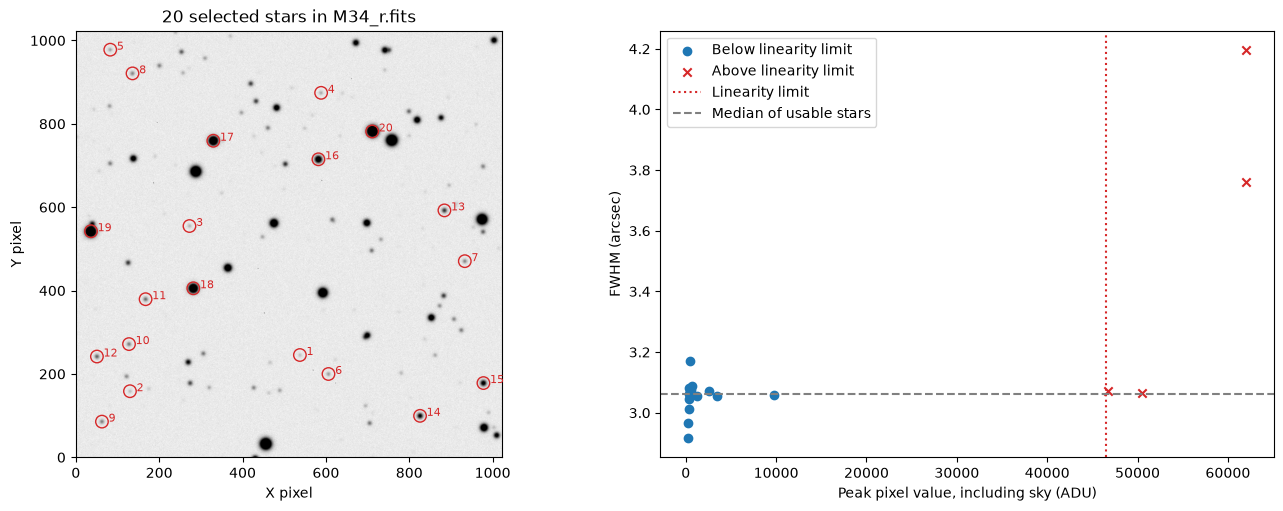

In [10]:
# Pick 20 isolated stars and find their FWHMs via photutils.psf.fit_fwhm.
positions, peak_counts = pick_stars(data, header['SATURATE'])
fwhm_pixels = measure_fwhm(data, positions)
fwhm_arcsec = fwhm_pixels * header['PIXSCALE']
linear = peak_counts < header['SATURATE']
valid = linear & np.isfinite(fwhm_pixels) & (fwhm_pixels > 1) & (fwhm_pixels < 20)
seeing = np.median(fwhm_arcsec[valid])
fwhm_table = Table([np.arange(1, len(positions) + 1), *positions.T,
                   peak_counts, fwhm_pixels, fwhm_arcsec, linear],
                  names=['star', 'x', 'y', 'peak_ADU', 'FWHM_pix', 'FWHM_arcsec', 'linear'])
fwhm_table.pprint(max_lines=-1, max_width=-1)
print(f'Median seeing (linear stars): {seeing:.3f} arcsec')

# Show the selected stars and plot FWHM versus each star's peak pixel value.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
axs[0].imshow(data, origin='lower', cmap='gray_r', norm=AsinhNorm(vmin=130, vmax=2000))
CircularAperture(positions, r=15).plot(ax=axs[0], color='tab:red', lw=1)
for number, (x, y) in enumerate(positions, start=1):
    axs[0].text(x + 16, y, str(number), color='tab:red', fontsize=8)
axs[0].set(xlabel='X pixel', ylabel='Y pixel', title='20 selected stars in M34_r.fits')
axs[1].scatter(peak_counts[linear], fwhm_arcsec[linear], label='Below linearity limit')
axs[1].scatter(peak_counts[~linear], fwhm_arcsec[~linear], marker='x',
               color='tab:red', label='Above linearity limit')
axs[1].axvline(header['SATURATE'], color='tab:red', ls=':', label='Linearity limit')
axs[1].axhline(seeing, color='gray', ls='--', label='Median of usable stars')
axs[1].set(xlabel='Peak pixel value, including sky (ADU)', ylabel='FWHM (arcsec)')
axs[1].legend()
plt.show()


#### 1.1 Written

Most of the stars labeled above have a similar FWHM, around 3.061 arcseconds. However, there are four (or so) relatively dim stars that have somewhat different FWHMs: stars 1, 2, and 5 have FWHMs about 0.05-0.15 lower than the median seeing (of stars in the linearity region). Star 8 has a FWHM around 3.18, which is a little high. This is likely because a low signal-to-noise ratio would lead to more variation in the FWHM fit.

However, none of these values are as egregious as the FWHMs obtained from the two brighest stars: they have FWHMs of around 3.76 (star 19) and 4.2 (star 20). These two stars in particular likely have far higher FWHMs because they are saturated. We compute the FWHM by fitting a two-dimensional profile, but if the pixels are saturated, then this can make the fitted profile appear wider than it actually is.

    frame     airmass N_stars      FWHM_pix        seeing_arcsec   
------------- ------- ------- ------------------ ------------------
M34_r_01.fits  2.1909       8 13.277569513483343  5.267211825998842
M34_r_02.fits  1.7793       8   9.48752872551578   3.76370264541211
M34_r_03.fits  1.5067       7  9.887375812540892  3.922321984834972
M34_r_04.fits  1.3201      10  9.656701507057988  3.830813487849904
M34_r_05.fits  1.1907       7  8.988578275699792 3.5657690019701076
M34_r_06.fits   1.094       7  8.270798355618062  3.281025707673685
M34_r_07.fits  1.0345       5  7.733802888208029  3.067999605752125
M34_r_08.fits  1.0035       8   7.71556838092299 3.0607659767121502


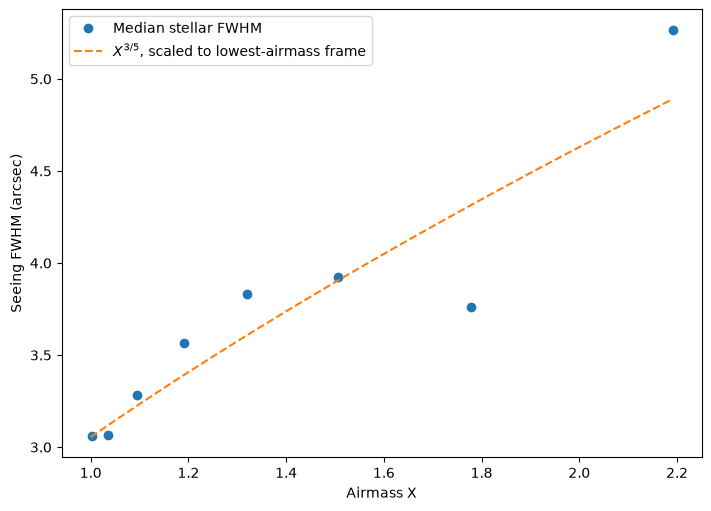

In [5]:
# Repeat the measurements for the eight seeing frames, using isolated linear stars.
frame_positions, frame_widths = [], []
rows = []
for path, frame, hdr in zip(seeing_paths, seeing_data, seeing_headers):
    xy, peaks = pick_stars(frame, hdr['SATURATE'], unsaturated=True)
    widths = measure_fwhm(frame, xy)
    good = np.isfinite(widths) & (widths > 1) & (widths < 20)
    frame_positions.append(xy[good])
    frame_widths.append(widths[good])
    rows.append((path.name, hdr['AIRMASS'], good.sum(),
                 np.median(widths[good]), np.median(widths[good]) * hdr['PIXSCALE']))
seeing_table = Table(rows=rows, names=['frame', 'airmass', 'N_stars', 'FWHM_pix', 'seeing_arcsec'])
seeing_table.pprint(max_lines=-1, max_width=-1)

# Scale X**(3/5) to the frame nearest the zenith (smallest airmass).
airmass = np.asarray(seeing_table['airmass'])
frame_seeing = np.asarray(seeing_table['seeing_arcsec'])
zenith_index = np.argmin(airmass)
x = np.linspace(1, airmass.max(), 200)
prediction = frame_seeing[zenith_index] * (x / airmass[zenith_index]) ** (3 / 5)
fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
ax.plot(airmass, frame_seeing, 'o', label='Median stellar FWHM')
ax.plot(x, prediction, '--', label=r'$X^{3/5}$, scaled to lowest-airmass frame')
ax.set(xlabel='Airmass X', ylabel='Seeing FWHM (arcsec)')
ax.legend()
plt.show()


#### 1.2 Written

Not exactly. The seeing generally increases with airmass, as predicted, but some frames differ from the curve. For example, the frame at an airmass of about 1.78 has better seeing than predicted, while the frame at about 2.19 has worse seeing. The atmosphere can change over the night, so airmass alone does not determine the seeing. Changes in focus could also contribute, but these measurements do not tell us the cause of the differences.


    frame           star_x             star_y      
------------- ------------------ ------------------
M34_r_01.fits  348.8283404404008 127.96312244355927
M34_r_02.fits 333.25912198098973 113.25533474236344
M34_r_03.fits 341.37277450987625    136.68288391395
M34_r_04.fits  353.2202644730692   129.960881877641
M34_r_05.fits   332.651689633229 135.49609970634282
M34_r_06.fits  347.3378171125848  130.5048427118546
M34_r_07.fits 331.33303774959046  133.6462747321385
M34_r_08.fits 336.29757850921885 136.87664605397265


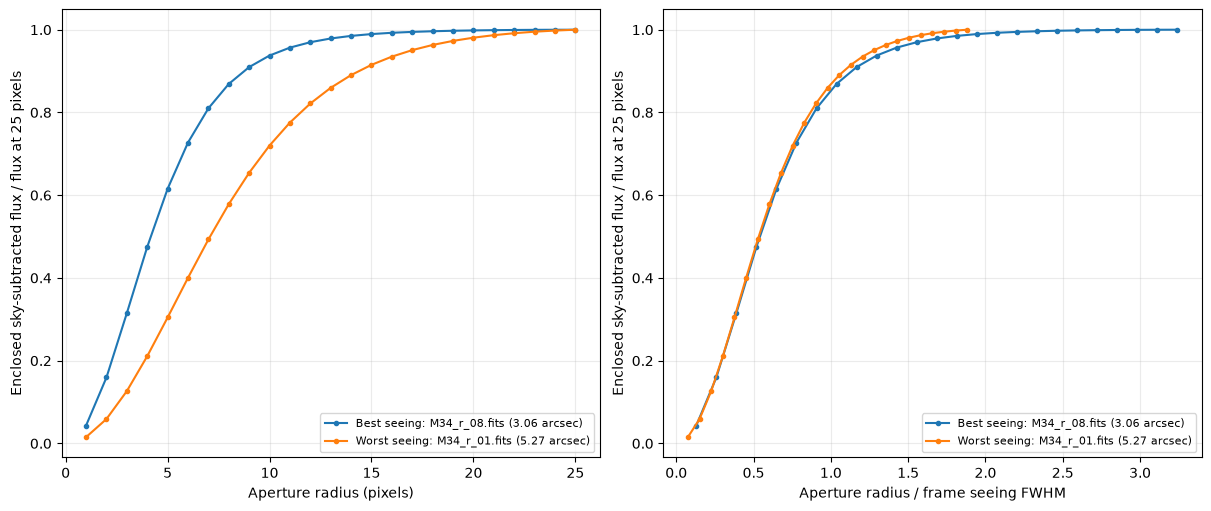

In [ ]:
# Pick the same isolated, unsaturated star in all eight frames using their WCS.
best_index, worst_index = np.argmin(frame_seeing), np.argmax(frame_seeing)
reference_xy = frame_positions[best_index]
reference_frame = seeing_data[best_index]
brightness = [reference_frame[int(round(y)), int(round(x))] for x, y in reference_xy]
for candidate in np.argsort(brightness)[::-1]:
    sky_position = WCS(seeing_headers[best_index]).pixel_to_world(*reference_xy[candidate])
    matched_positions = []
    for hdr, xy in zip(seeing_headers, frame_positions):
        predicted_xy = np.array(WCS(hdr).world_to_pixel(sky_position))
        distances = np.linalg.norm(xy - predicted_xy, axis=1)
        nearest = np.argmin(distances)
        if distances[nearest] > 5:
            break
        matched_positions.append(xy[nearest])
    if len(matched_positions) == len(seeing_paths):
        break
else:
    raise ValueError('No isolated linear star matched in every seeing frame.')

Table(rows=[(path.name, *xy) for path, xy in zip(seeing_paths, matched_positions)],
      names=['frame', 'star_x', 'star_y']).pprint(max_lines=-1)





# Curves of growth: hold the background annulus fixed outside every aperture.
radii = np.arange(1, 26, dtype=float)
fig, axs = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
growth_curves = {}
for label, index in [('Best seeing', best_index), ('Worst seeing', worst_index)]:
    frame, xy = seeing_data[index], matched_positions[index]
    annulus = CircularAnnulus(xy, r_in=27, r_out=33)
    flux = np.array([background_subtracted_sum(frame, CircularAperture(xy, r=r), annulus)
                     for r in radii])
    growth_curves[label] = flux
    fraction = flux / flux[-1]  # normalize each curve at the same largest radius
    frame_fwhm = seeing_table['FWHM_pix'][index]
    curve_label = f"{label}: {seeing_paths[index].name} ({frame_seeing[index]:.2f} arcsec)"
    axs[0].plot(radii, fraction, 'o-', ms=3, label=curve_label)
    axs[1].plot(radii / frame_fwhm, fraction, 'o-', ms=3, label=curve_label)
axs[0].set_xlabel('Aperture radius (pixels)')
axs[1].set_xlabel('Aperture radius / frame seeing FWHM')
for ax in axs:
    ax.set_ylabel('Enclosed sky-subtracted flux / flux at 25 pixels')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
plt.show()


#### 1.3 Written

A fixed 10-px aperture holds about 94% of the light of the given star in frame with the best seeing and around 72% in the frame with the worst seeing. The plots suggest that as seeing increases, we need to increase the aperture radius to capture close to all the light of the star. The curves nearly overlap in FWHM units, suggesting that we should keep the aperture radius proportional to the seeing.

### Part 2

center        : area = 81.000000, pi*r^2 = 78.539816, fractional difference = +0.031324
subpixel (5)  : area = 79.040000, pi*r^2 = 78.539816, fractional difference = +0.00636854
exact         : area = 78.539816, pi*r^2 = 78.539816, fractional difference = +0


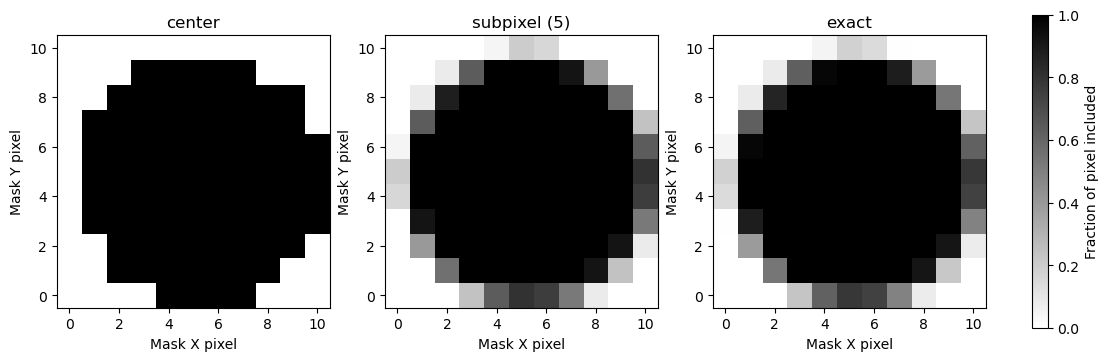

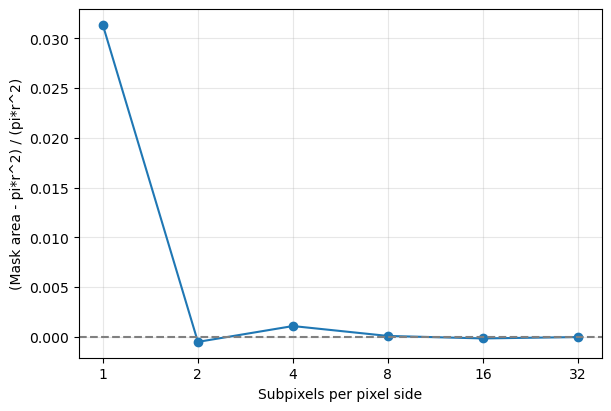

In [7]:
# Make a CircularAperture of radius 5 pixels centered at (50.3, 50.7)
aperture = CircularAperture((50.3, 50.7), r=5)
# Display its masks for "center" , "subpixel" with subpixels=5 , and "exact" side by side (an aperture's to_mask method makes these). 
masks = {
    'center': aperture.to_mask(method='center'),
    'subpixel (5)': aperture.to_mask(method='subpixel', subpixels=5),
    'exact': aperture.to_mask(method='exact'),
}
fig, axs = plt.subplots(1, 3, figsize=(11, 4), layout='constrained')
# Sum each mask, which gives the area the aperture actually covers, and compare it with pi r^2. 
for ax, (method, mask) in zip(axs, masks.items()):
    image = ax.imshow(mask.data, origin='lower', vmin=0, vmax=1, cmap='gray_r')
    ax.set(title=method, xlabel='Mask X pixel', ylabel='Mask Y pixel')
    area = mask.data.sum()
    print(f'{method:14s}: area = {area:.6f}, pi*r^2 = {aperture.area:.6f}, '
          f'fractional difference = {(area / aperture.area - 1):+.6g}')
fig.colorbar(image, ax=axs, label='Fraction of pixel included', shrink=0.8)
plt.show()

# Repeat the sum for "subpixel" with subpixels = 1, 2, 4, 8, 16 and 32, 
subpixel_counts = np.array([1, 2, 4, 8, 16, 32])
# Plot the fractional difference from against subpixels.
subpixel_areas = np.array([aperture.to_mask(method='subpixel', subpixels=int(s)).data.sum()
                           for s in subpixel_counts])
# Compute the fractional difference
fractional_differences = subpixel_areas / aperture.area - 1
# Plot
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
ax.plot(subpixel_counts, fractional_differences, 'o-')
ax.axhline(0, color='gray', ls='--')
ax.set_xscale('log', base=2)
ax.set_xticks(subpixel_counts, labels=subpixel_counts)
ax.set(xlabel='Subpixels per pixel side', ylabel='(Mask area - pi*r^2) / (pi*r^2)')
ax.grid(alpha=0.3)
plt.show()


#### 2.1 Written

The pixels which differ between "center," "subpixel", and "exact" modes are the pixels at the very edge of the aperture: i.e. the pixels which are partly inside the aperture and partially no. Center appears to include/exclude pixels based on whether their center is within the aperture, while subpixels 5 splits the pixel into a 5x5 grid and evaluates their centers, and the last uses the exact proportion of the pixel within the aperture.


The method with subpixels = 1 is the same as the center method.


radius_pix         center              subpixel_5               exact        
---------- --------------------- ---------------------- ---------------------
         2   0.08330174826786504   0.006492661087499109 8.679803165675326e-17
         4  0.026417222411143016  0.0024693593781089733   8.5652132794736e-17
         8  0.010608595015296582  0.0007924638278409425 6.480140432886166e-17
        16 0.0032624053866893944 0.00029814588560870474 6.904601392326432e-17
Center-method log-log slope: -1.53


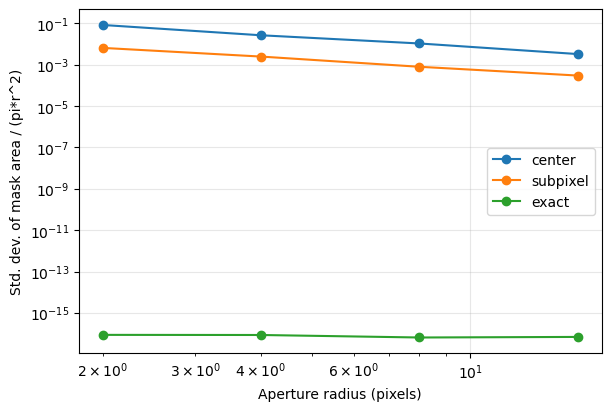

In [8]:
# Radii of 2,4,8,16 pixels: 
rng = np.random.default_rng(410)
# place the circle at a few hundred random centers and measure the scatter of its area as a fraction of pi*r^2
random_centers = rng.uniform(50, 51, size=(500, 2))
area_radii = np.array([2, 4, 8, 16])
area_scatter = {method: [] for method in ['center', 'subpixel', 'exact']}
for radius in area_radii:
    circles = CircularAperture(random_centers, r=radius)
    for method in area_scatter:
        weights = circles.to_mask(method=method, subpixels=5)
        fractional_areas = np.array([mask.data.sum() for mask in weights]) / circles.area
        area_scatter[method].append(np.std(fractional_areas, ddof=1))
area_scatter_table = Table([area_radii, *area_scatter.values()],
                           names=['radius_pix', 'center', 'subpixel_5', 'exact'])
area_scatter_table.pprint(max_lines=-1)
area_slope = np.polyfit(np.log(area_radii), np.log(area_scatter['center']), 1)[0]
print(f'Center-method log-log slope: {area_slope:.2f}')
# Plot the scatter against radius on logarithmic axes
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for method, scatter in area_scatter.items():
    ax.loglog(area_radii, scatter, 'o-', label=method)
ax.set(xlabel='Aperture radius (pixels)', ylabel='Std. dev. of mask area / (pi*r^2)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()


#### 2.2 Written

As the aperture size increases, the std. dev of mask area decreases, as we expect. The center and subpixel methods include/exclude pixels/parts of pixels, so the more we have, the fewer are on the boundary, as a function of the total number of pixels illuminated. The measured slope is about −1.53. The number of boundary pixels grows roughly as the radius, so random boundary errors grow roughly as its square root; dividing by the aperture area gives fractional scatter proportional to approximately $r^{-3/2}$.

Bright star centroid: (364.958, 454.558); aperture radius = 7.715 pixels (1 FWHM)
center: mean flux = 1020022.4 ADU, fractional scatter = 0.002673
exact : mean flux = 1018786.1 ADU, fractional scatter = 0.000846
center: Eq. (1) uncertainty = 1026.3 ADU (0.101%); position scatter / Eq. (1) uncertainty = 2.66
exact : Eq. (1) uncertainty = 1025.7 ADU (0.101%); position scatter / Eq. (1) uncertainty = 0.84


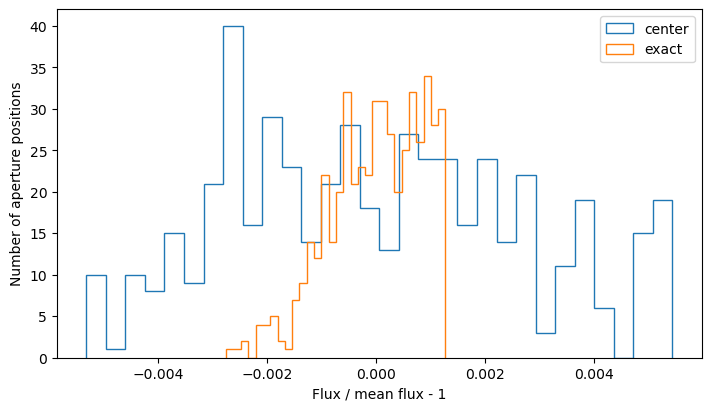

In [9]:
# bright, unsatured star in M34_r.fits
from photutils.centroids import centroid_sources, centroid_2dg
bright_positions, bright_peaks = pick_stars(data, header['SATURATE'], n=100, unsaturated=True)
bright_guess = bright_positions[np.argmax(bright_peaks)]
_, sky_level, _ = sigma_clipped_stats(data)
xc, yc = centroid_sources(data - sky_level, *bright_guess, box_size=21, centroid_func=centroid_2dg)

bright_xy = np.array([xc[0], yc[0]])
main_fwhm = np.median(fwhm_pixels[valid])
print(f'Bright star centroid: ({bright_xy[0]:.3f}, {bright_xy[1]:.3f}); '
      f'aperture radius = {main_fwhm:.3f} pixels (1 FWHM)')

# Measure star's flux in aperture of radius 1 FWHM with both "center" and "exact" a few hundred, each time moving the aperture to a random position within half a pixel of the star's centroid.
shifted_centers = bright_xy + rng.uniform(-0.5, 0.5, size=(500, 2))
shifted_apertures = CircularAperture(shifted_centers, r=main_fwhm)
bright_annulus = CircularAnnulus(bright_xy, r_in=3 * main_fwhm, r_out=4 * main_fwhm)
sky_table = aperture_photometry(data, bright_annulus, method='exact')
bright_sky = sky_table['aperture_sum'][0] / bright_annulus.area
jitter_fluxes = {}

for method in ['center', 'exact']:
    sums = np.asarray(aperture_photometry(data, shifted_apertures, method=method)['aperture_sum'])
    areas = np.array([mask.data.sum() for mask in shifted_apertures.to_mask(method=method)])
    fluxes = sums - bright_sky * areas
    jitter_fluxes[method] = fluxes
    print(f'{method:6s}: mean flux = {fluxes.mean():.1f} ADU, '
          f'fractional scatter = {fluxes.std(ddof=1) / fluxes.mean():.6f}')
_, _, star_sky_scatter = sigma_clipped_stats(bright_annulus.to_mask(method='center').get_values(data))
for method, fluxes in jitter_fluxes.items():
    expected_noise = np.sqrt(fluxes.mean() + np.pi * main_fwhm**2 * star_sky_scatter**2)
    print(f'{method:6s}: Eq. (1) uncertainty = {expected_noise:.1f} ADU '
          f'({100 * expected_noise / fluxes.mean():.3f}%); '
          f'position scatter / Eq. (1) uncertainty = {fluxes.std(ddof=1) / expected_noise:.2f}')

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')


for method, fluxes in jitter_fluxes.items():
    ax.hist(fluxes / fluxes.mean() - 1, bins=30, histtype='step', label=method)
ax.set(xlabel='Flux / mean flux - 1', ylabel='Number of aperture positions')
ax.legend()
plt.show()


#### 2.3 Written

The exact method has far lower variance in the flux measurement than the "center" method. The fractional scatter is about 0.267% for center and 0.0846% for exact, compared with an expected uncertainty of about 0.101% from Eq. (1). Thus, the center-method scatter exceeds the expected noise, while the exact-method scatter is smaller. The choice of the method could be particularly important when we are trying to measure a flux change between frames --- e.g. exoplanet detection.

### Part 3

107 detections; sky scatter = 13.774 ADU; detection FWHM = 7.715 pixels


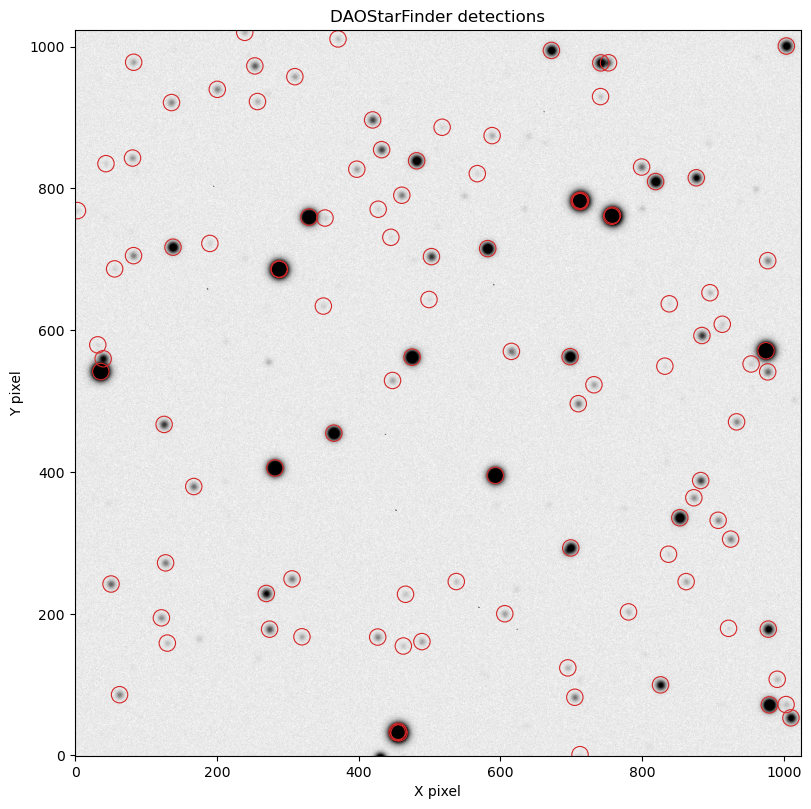

In [10]:
# Find stars in M34_r.fits with photoutils.detection.DAOStarFinder using a threshold of 5 times the sky scatter with FWHM aperture (measure in part 1)
_, detection_sky, sky_scatter = sigma_clipped_stats(data)
finder = DAOStarFinder(fwhm=main_fwhm, threshold=5 * sky_scatter)
detections = finder(data - detection_sky)
detection_xy = np.column_stack((detections['xcentroid'], detections['ycentroid']))
print(f'{len(detections)} detections; sky scatter = {sky_scatter:.3f} ADU; '
      f'detection FWHM = {main_fwhm:.3f} pixels')
# Plot
fig, ax = plt.subplots(figsize=(8, 8), layout='constrained')
ax.imshow(data, origin='lower', cmap='gray_r', norm=AsinhNorm(vmin=130, vmax=2000))
CircularAperture(detection_xy, r=1.5 * main_fwhm).plot(ax=ax, color='tab:red', lw=0.8)
ax.set(xlabel='X pixel', ylabel='Y pixel', title='DAOStarFinder detections')
plt.show()


#### 3.1 Written

It's unclear whether everything found is a star --- there are a few apertures around seemingly tiny dots, which could be unusually hot pixels; however, most of the apertures seem to be around stars. There are seemingly some dimmer stars that are not detected (e.g. there's one around x = 260, y = 460). 

In [11]:
# Write sky_subtracted_flux , and use it to measure every detection at once with an aperture of radius 1.5 FWHM.
def sky_subtracted_flux(data, apertures, annuli):
    """Subtract median annular sky and return fluxes and Eq. (1) errors (1 electron/ADU)."""
    sums = np.asarray(aperture_photometry(data, apertures, method='exact')['aperture_sum'])
    masks = annuli.to_mask(method='center')
    if not isinstance(masks, list):
        masks = [masks]
    sky_medians, sky_variances = [], []
    for mask in masks:
        samples = mask.get_values(data)
        samples = samples[np.isfinite(samples)]
        if len(samples) > 1:
            _, median, std = sigma_clipped_stats(samples)
        else:
            median, std = np.nan, np.nan
        sky_medians.append(median)
        sky_variances.append(std**2)
    flux = sums - apertures.area * np.array(sky_medians)
    flux_error = np.sqrt(np.maximum(flux, 0) + apertures.area * np.array(sky_variances))
    return flux, flux_error

phot_radius, sky_inner, sky_outer = 1.5 * main_fwhm, 3 * main_fwhm, 4 * main_fwhm
phot_apertures = CircularAperture(detection_xy, r=phot_radius)
phot_annuli = CircularAnnulus(detection_xy, r_in=sky_inner, r_out=sky_outer)
flux, flux_error = sky_subtracted_flux(data, phot_apertures, phot_annuli)
# Convert each flux into m_inst and sigma_m. via m = m_inst + ZP and m_inst = -2.5 * log10(N/t), where ZP is the magnitude of a star that gives one ADU per second.
m_inst = np.full(len(flux), np.nan)
sigma_m = np.full(len(flux), np.nan)
positive_flux = np.isfinite(flux) & (flux > 0)
m_inst[positive_flux] = -2.5 * np.log10(flux[positive_flux] / header['EXPTIME'])
sigma_m[positive_flux] = (2.5 / np.log(10)) * flux_error[positive_flux] / flux[positive_flux]
photometry = detections.copy()
photometry['flux_ADU'], photometry['flux_error_ADU'] = flux, flux_error
photometry['m_inst'], photometry['sigma_m'] = m_inst, sigma_m

# Convert the catalog positions into pixels with the WCS in the header, and match each catalog star to the nearest Print how many match
catalog = Table.read(data_path / 'M34_catalog.csv', format='ascii.csv')
cat_x, cat_y = WCS(header).all_world2pix(catalog['ra'], catalog['dec'], 0)
catalog_xy = np.column_stack((cat_x, cat_y))
match_distances = cdist(catalog_xy, detection_xy)
nearest = np.argmin(match_distances, axis=1)
separation = match_distances[np.arange(len(catalog)), nearest]
matched = separation < 2
for detection_index in np.unique(nearest[matched]):
    candidates = np.flatnonzero(matched & (nearest == detection_index))
    if len(candidates) > 1:
        matched[candidates[np.argsort(separation[candidates])[1:]]] = False
matched_catalog = catalog[matched].copy()
matched_indices = nearest[matched]
matched_catalog['detection_id'] = detections['id'][matched_indices]
matched_catalog['separation_pix'] = separation[matched]
matched_catalog['m_inst'] = m_inst[matched_indices]
matched_catalog['sigma_m'] = sigma_m[matched_indices]
print(f'Matched {matched.sum()} of {len(catalog)} catalog stars within 2 pixels.')
matched_catalog.pprint(max_lines=-1, max_width=-1)


Matched 100 of 174 catalog stars within 2 pixels.
 id     ra       dec    r_mag  r_err detection_id    separation_pix           m_inst              sigma_m        
--- --------- --------- ------ ----- ------------ -------------------- ------------------- ----------------------
  1 40.524071 42.707391  8.272 0.008            2   1.2950137505583044 -13.063218360619258  0.0003440157186325774
  2 40.493508 42.791819  8.426 0.008           81   1.0135512952836374 -12.991170284796175  0.0003559635723642696
  3 40.486431 42.789786  8.473 0.008           75   1.0654141146677052  -12.95959011350039  0.0003610746670536234
  4 40.556082 42.777929  8.746 0.008           65   0.4583060370954232 -12.797907277428479  0.0003887387237838003
  5 40.592284 42.760133  8.819 0.008           47  0.34353294379523336 -12.752137726005914 0.00039750711568832786
  6 40.452022  42.77058  8.953 0.008           54  0.18002752983089124  -12.66994346281635 0.00041324332853547756
  7 40.507381 42.748307  9.639 0.008  

#### 3.2 Written

About 100 stars match. This is a little less than I was expecting, though seems somewhat reasonable.

ZP = 21.7651 +/- 0.0021 mag (36 stars); formal error = 0.0020, reduced chi^2 = 1.07
 id         ZP         used_for_ZP                                  exclusion_reason                                
--- ------------------ ----------- ---------------------------------------------------------------------------------
  1  21.33521836061926       False                                           above linearity limit; nearby detection
  2 21.417170284796175       False                                           above linearity limit; nearby detection
  3  21.43259011350039       False                                           above linearity limit; nearby detection
  4  21.54390727742848       False                                           above linearity limit; nearby detection
  5 21.571137726005915       False                                           above linearity limit; nearby detection
  6  21.62294346281635       False                                           above linearity limi

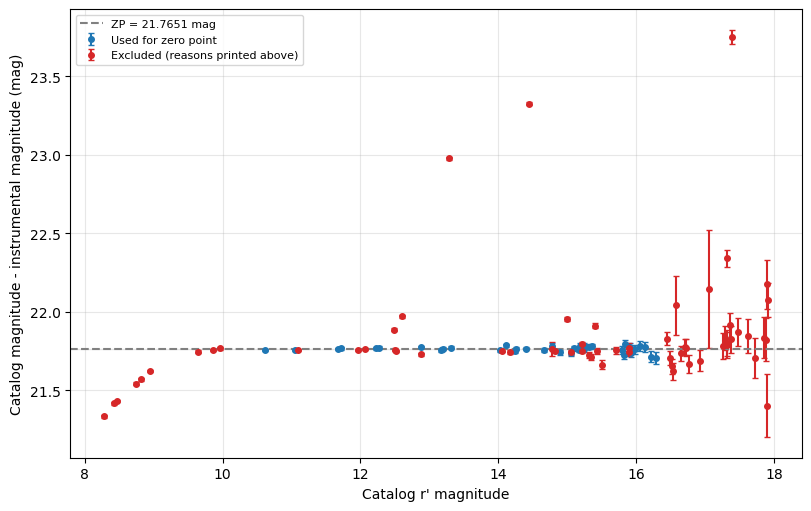

In [12]:
# Plot against catalog magnitude , with error bars. Find the zero point from the stars you
# trust, say which you left out and why, and report with its uncertainty.
ny, nx = data.shape

edge = ((detection_xy[:, 0] < sky_outer) | (detection_xy[:, 0] > nx - 1 - sky_outer) |
        (detection_xy[:, 1] < sky_outer) | (detection_xy[:, 1] > ny - 1 - sky_outer))
peak_pixels = []

for x, y in detection_xy:
    ix, iy = int(round(x)), int(round(y))
    peak_pixels.append(data[max(0, iy-3):min(ny, iy+4), max(0, ix-3):min(nx, ix+4)].max())
saturated = np.array(peak_pixels) >= header['SATURATE']
distances = cdist(detection_xy, detection_xy)
np.fill_diagonal(distances, np.inf)
crowded = distances.min(axis=1) < sky_outer + main_fwhm
low_snr = ~positive_flux | (flux / flux_error < 30)
reasons = []


for index in matched_indices:
    flags = [name for name, mask in [('above linearity limit', saturated),
             ('aperture/sky annulus crosses edge', edge), ('nearby detection', crowded),
             ('S/N below 30 or invalid flux', low_snr)] if mask[index]]
    reasons.append('; '.join(flags) if flags else '')
trusted = np.array([reason == '' for reason in reasons])
individual_zp = np.asarray(matched_catalog['r_mag'] - matched_catalog['m_inst'])
zp_errors = np.hypot(matched_catalog['r_err'], matched_catalog['sigma_m'])


if trusted.sum() < 2:
    raise ValueError('Fewer than two reliable zero-point calibrators.')
initial_zp = np.median(individual_zp[trusted])
outliers = trusted & (np.abs(individual_zp - initial_zp) > 5 * zp_errors)


for i in np.flatnonzero(outliers):
    reasons[i] = 'zero-point residual exceeds 5 sigma from initial median'
trusted &= ~outliers


if trusted.sum() < 2:
    raise ValueError('Fewer than two calibrators remain after the residual check.')
weights = 1 / zp_errors[trusted]**2
zero_point = np.average(individual_zp[trusted], weights=weights)
chi2 = np.sum(weights * (individual_zp[trusted] - zero_point)**2)
reduced_chi2 = chi2 / (trusted.sum() - 1)
formal_zp_error = 1 / np.sqrt(weights.sum())
zero_point_error = formal_zp_error * np.sqrt(max(1, reduced_chi2))
matched_catalog['ZP'] = individual_zp
matched_catalog['used_for_ZP'] = trusted
matched_catalog['exclusion_reason'] = reasons
print(f'ZP = {zero_point:.4f} +/- {zero_point_error:.4f} mag ({trusted.sum()} stars); '
      f'formal error = {formal_zp_error:.4f}, reduced chi^2 = {reduced_chi2:.2f}')
matched_catalog[['id', 'ZP', 'used_for_ZP', 'exclusion_reason']].pprint(max_lines=-1, max_width=-1)
print('Unmatched catalog IDs:', list(catalog['id'][~matched]))

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')




for use, label, color in [(True, 'Used for zero point', 'tab:blue'),
                           (False, 'Excluded (reasons printed above)', 'tab:red')]:
    mask = (trusted == use) & np.isfinite(individual_zp)
    ax.errorbar(matched_catalog['r_mag'][mask], individual_zp[mask], yerr=zp_errors[mask],
                fmt='o', ms=4, capsize=2, color=color, label=label)
ax.axhline(zero_point, color='gray', ls='--', label=f'ZP = {zero_point:.4f} mag')
ax.axhspan(zero_point - zero_point_error, zero_point + zero_point_error, color='gray', alpha=0.2)
ax.set(xlabel="Catalog r' magnitude", ylabel="Catalog magnitude - instrumental magnitude (mag)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()



photometry['r_calibrated'] = m_inst + zero_point
photometry['sigma_r_calibrated'] = np.hypot(sigma_m, zero_point_error)


#### 3.3 Written

Our zero point is $21.7651 \pm 0.0021$ mag. Our zero magnitude agrees at (catalogue) magnitudes from about 9.5 to 17. Below 9.5, stars become saturated, meaning that the detector underestimates their brightness (and thus assumes they have a higher magnitude than they actually do). At high magnitudes, noise becomes a dominating factor, and stars may appear significantly dimmer or brighter because of measurement noise or contamination from nearby stars. For the stars used in the fit, the scatter is consistent with the error bars: the reduced chi-squared is about 1.07. Saturated stars and several contaminated measurements disagree with the zero point by much more than their error bars.

Flux within 1.5 FWHM / flux within 3 FWHM = 0.96446
Magnitude difference m(1.5 FWHM) - m(3 FWHM) = 0.03929 mag


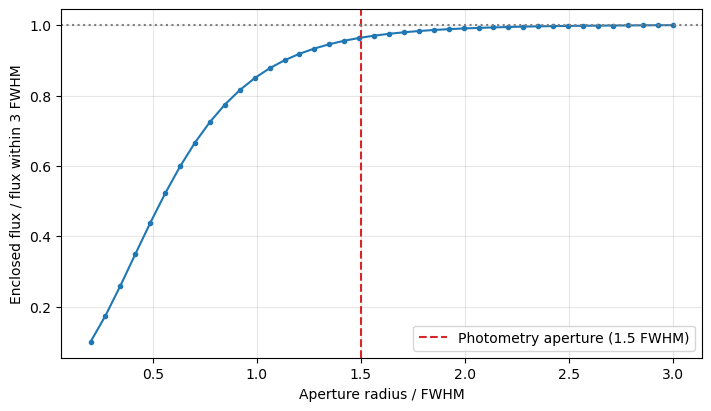

In [13]:
# Plot curve of bright, unsaturated star in terms of FWHM.
growth_radii_fwhm = np.linspace(0.2, 3, 40)
growth_radii_pixels = growth_radii_fwhm * main_fwhm
growth_annulus = CircularAnnulus(bright_xy, r_in=3.5 * main_fwhm, r_out=4.5 * main_fwhm)
bright_growth_flux = np.array([background_subtracted_sum(
    data, CircularAperture(bright_xy, r=r), growth_annulus) for r in growth_radii_pixels])
normalization_flux = bright_growth_flux[-1]
flux_at_phot_radius = background_subtracted_sum(
    data, CircularAperture(bright_xy, r=phot_radius), growth_annulus)
enclosed_fraction = flux_at_phot_radius / normalization_flux
print(f'Flux within 1.5 FWHM / flux within 3 FWHM = {enclosed_fraction:.5f}')
print(f'Magnitude difference m(1.5 FWHM) - m(3 FWHM) = '
      f'{-2.5 * np.log10(enclosed_fraction):.5f} mag')
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(growth_radii_fwhm, bright_growth_flux / normalization_flux, 'o-', ms=3)
ax.axvline(1.5, color='tab:red', ls='--', label='Photometry aperture (1.5 FWHM)')
ax.axhline(1, color='gray', ls=':')
ax.set(xlabel='Aperture radius / FWHM', ylabel='Enclosed flux / flux within 3 FWHM')
ax.legend()
ax.grid(alpha=0.3)
plt.show()


#### 3.4 Written

The aperture of radius 1.5 FWHM holds about 96.45% of the light measured within 3 FWHM, so it misses about 3.55%. Correcting the measured flux upward would make the instrumental magnitude about 0.039 mag smaller, so our zero point would increase by about 0.039 mag. If we only compare stars measured with the same aperture, this correction cancels as long as the aperture holds the same fraction of each star's light.
